# Two-envelope paradox: conditional probability

Two envelopes contain $X$ and $2X$, where $X>0$ is the smaller amount. You choose an envelope at random. Its amount is $A$; the other amount is $B$.

Before you open it, you have a $1/2$ chance of holding the smaller amount. After you see $A=a$, that chance can change. The amount tells you something about which pair you received.

Run the cells from top to bottom. The first picture counts games exactly; the simulation then samples games at random.

## The tempting argument

You see $a$. The other envelope could contain $2a$ or $a/2$. Giving each possibility probability $1/2$ gives the **incorrect** calculation

$$E[B\mid A=a]\overset{\text{wrong}}{=}\tfrac12(2a)+\tfrac12(a/2)=\tfrac54a>a.$$

This suggests always switching. After switching, the same argument seems to recommend switching back.

The mistake is assigning equal probabilities to the two possibilities after seeing the amount. Two possible outcomes need not be equally likely.

## Count the games before using Bayes' rule

Suppose the pair is $(100,200)$ with probability $0.9$ and $(200,400)$ with probability $0.1$. Within either pair, you choose each envelope with probability $1/2$.

Build a batch of 100 games with exactly those proportions. This is a count of the model's probabilities, not a random sample.

| Pair | Chosen amount $A$ | Other amount $B$ | Games | Change if you switch |
|---|---:|---:|---:|---:|
| $(100,200)$ | 100 | 200 | 45 | $+100$ |
| $(100,200)$ | 200 | 100 | 45 | $-100$ |
| $(200,400)$ | 200 | 400 | 5 | $+200$ |
| $(200,400)$ | 400 | 200 | 5 | $-200$ |

Across all 100 games, switching wins in 50 and loses in 50. Now keep only games where you opened 200: the second and third rows remain.

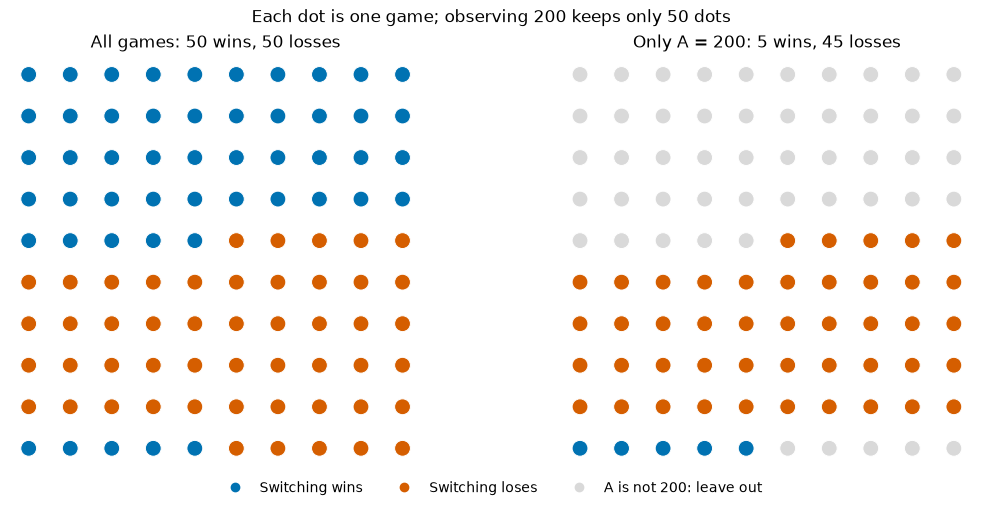

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Repeat each possible outcome according to its probability out of 100.
exact_A = np.repeat([100, 200, 200, 400], [45, 45, 5, 5])
exact_B = np.repeat([200, 100, 400, 200], [45, 45, 5, 5])
seen_200 = exact_A == 200
wins = exact_B > exact_A

assert wins.sum() == 50
assert seen_200.sum() == 50
assert (wins & seen_200).sum() == 5
assert exact_B[seen_200].mean() == 130

blue, orange, gray = '#0072B2', '#D55E00', '#D9D9D9'
colors = np.where(wins, blue, orange)
positions = np.arange(100)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for ax, dot_colors, title in zip(
    axes,
    [colors, np.where(seen_200, colors, gray)],
    ['All games: 50 wins, 50 losses', 'Only A = 200: 5 wins, 45 losses'],
):
    ax.scatter(positions % 10, -(positions // 10), c=dot_colors, s=130,
               edgecolors='white', linewidths=0.7)
    ax.set(title=title, aspect='equal')
    ax.set_axis_off()

legend = [
    Line2D([], [], marker='o', linestyle='', color=color, label=label)
    for color, label in [(blue, 'Switching wins'), (orange, 'Switching loses'),
                         (gray, 'A is not 200: leave out')]
]
fig.legend(handles=legend, loc='outside lower center', ncols=3, frameon=False)
fig.suptitle('Each dot is one game; observing 200 keeps only 50 dots')
plt.show()

Among the 50 games that show 200, switching gives 400 in 5 games and 100 in 45 games:

$$P(B=400\mid A=200)=\frac{5}{50}=0.1,\qquad P(B=100\mid A=200)=\frac{45}{50}=0.9.$$

So the average amount after switching is

$$E[B\mid A=200]=\frac{5(400)+45(100)}{50}=130.$$

Keeping gives 200 every time in this group. Switching gains 200 in 5 games and loses 100 in 45 games, for an average change of $-70$.

The coin used to choose an envelope is fair. But seeing 200 selects a group with far more games from the common $(100,200)$ pair. No money or envelope changed; you learned which games are still possible.

## Simulate the same experiment

Each game needs two independent random choices: choose the pair, then choose an envelope. Only afterward do we filter for $A=200$.

The seed makes the results repeatable. Change it or increase `n_games` and rerun from this cell to get another sample. Larger samples usually come closer to the exact probabilities.

In [2]:
rng = np.random.default_rng(42)
n_games = 100_000

X = rng.choice([100, 200], size=n_games, p=[0.9, 0.1])
picked_smaller = rng.integers(0, 2, size=n_games) == 0
A = np.where(picked_smaller, X, 2 * X)
B = np.where(picked_smaller, 2 * X, X)
observed = A == 200

assert np.all(A + B == 3 * X)
assert np.all((B == 2 * A) | (A == 2 * B))

print(f'Total games: {n_games:,}')
print(f'Chance switching wins, before observing: {(B > A).mean():.3f} (exact: 0.5)')
print(f'Games showing A = 200: {observed.sum():,}')
for other_amount, exact_probability in [(100, 0.9), (400, 0.1)]:
    count = np.count_nonzero(observed & (B == other_amount))
    print(f'  B = {other_amount}: {count:,} games, '
          f'probability {count / observed.sum():.3f} (exact: {exact_probability})')
print(f'Average B when A = 200: {B[observed].mean():.2f} (exact: 130)')

Total games: 100,000
Chance switching wins, before observing: 0.502 (exact: 0.5)
Games showing A = 200: 49,851
  B = 100: 44,793 games, probability 0.899 (exact: 0.9)
  B = 400: 5,058 games, probability 0.101 (exact: 0.1)
Average B when A = 200: 130.44 (exact: 130)


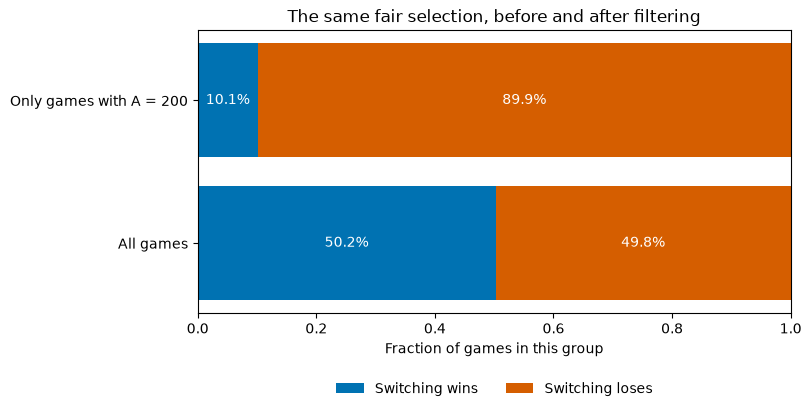

In [3]:
groups = ['All games', 'Only games with A = 200']
win_rates = [(B > A).mean(), (B[observed] > A[observed]).mean()]
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.barh(groups, win_rates, color=blue, label='Switching wins')
ax.barh(groups, 1 - np.array(win_rates), left=win_rates,
        color=orange, label='Switching loses')
for row, rate in enumerate(win_rates):
    ax.text(rate / 2, row, f'{rate:.1%}', ha='center', va='center', color='white')
    ax.text((1 + rate) / 2, row, f'{1 - rate:.1%}',
            ha='center', va='center', color='white')
ax.set(xlim=(0, 1), xlabel='Fraction of games in this group',
       title='The same fair selection, before and after filtering')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncols=2,
          frameon=False)
plt.show()

The first bar uses every game. The second uses only games showing 200. That change of group is what the vertical bar in $P(B=400\mid A=200)$ means: count only the games where $A=200$.

## Bayes' rule gives the same count

Write $p(x)=P(X=x)$ for the probability that the smaller amount is $x$. Here, $p(100)=0.9$, $p(200)=0.1$, and $p(x)=0$ for other values.

For discrete amounts, an observation $A=a$ can come from two cases:

| Case | Smaller amount | Chance before observing | Other envelope |
|---|---|---|---|
| You picked the smaller envelope | $X=a$ | $\tfrac12p(a)$ | $B=2a$ |
| You picked the larger envelope | $X=a/2$ | $\tfrac12p(a/2)$ | $B=a/2$ |

Divide each case's probability by their sum, assuming $P(A=a)>0$:

$$P(B=2a\mid A=a)=\frac{\frac12p(a)}{\frac12p(a)+\frac12p(a/2)}=\frac{p(a)}{p(a)+p(a/2)}.$$

$$P(B=a/2\mid A=a)=\frac{p(a/2)}{p(a)+p(a/2)}.$$

The $1/2$ factors cancel. Equal chances of picking either envelope do not imply equal chances for the two original pairs.

$$E[B\mid A=a]=\frac{2a\,p(a)+(a/2)\,p(a/2)}{p(a)+p(a/2)}.$$

With $a=200$, the two ways to see 200 have probabilities $0.1(1/2)=0.05$ and $0.9(1/2)=0.45$. Their sum is $P(A=200)=0.5$.

$$P(B=400\mid A=200)=\frac{0.05}{0.5}=0.1,\qquad P(B=100\mid A=200)=\frac{0.45}{0.5}=0.9.$$

$$E[B\mid A=200]=0.1(400)+0.9(100)=130<200.$$

The wrong calculation would give 250. It gives the rare $(200,400)$ pair the same weight as the nine-times-more-common $(100,200)$ pair.

## Check every possible observation

The correct decision here maximizes the expected amount you keep.

| You see $A$ | Probability of seeing it | Possible $B$ | $E[B\mid A]$ | Average change from switching | Decision |
|---:|---:|---|---:|---:|---|
| 100 | 0.45 | 200 for certain | 200 | $+100$ | Switch |
| 200 | 0.50 | 100 with probability 0.9; 400 with probability 0.1 | 130 | $-70$ | Keep |
| 400 | 0.05 | 200 for certain | 200 | $-200$ | Keep |

Seeing 100 guarantees you have the smaller envelope. Seeing 400 guarantees you have the larger one. Seeing 200 leaves both possibilities, with unequal probabilities.

In [4]:
print(f'{"A seen":>8} {"Games":>10} {"Average B":>12} {"Switch change":>15}')
for amount in np.unique(A):
    group = A == amount
    print(f'{amount:8d} {group.sum():10,d} {B[group].mean():12.2f} '
          f'{(B[group] - A[group]).mean():+15.2f}')

# The exact 100-game batch checks all rows without sampling noise.
for amount, probability, expected_B in [(100, 0.45, 200), (200, 0.5, 130),
                                         (400, 0.05, 200)]:
    group = exact_A == amount
    assert group.mean() == probability
    assert exact_B[group].mean() == expected_B

  A seen      Games    Average B   Switch change
     100     45,164       200.00         +100.00
     200     49,851       130.44          -69.56
     400      4,985       200.00         -200.00


## Before opening, either envelope has the same average

For a fixed pair $(X,2X)$, switching gains $X$ half the time and loses $X$ half the time. Before observing, $P(A<B)=P(A>B)=1/2$ and $E[A]=E[B]$ when the expectations are finite.

In this model, $E[X]=0.9(100)+0.1(200)=110$, so

$$E[A]=E[B]=\tfrac32E[X]=165.$$

The conditional switching gains also cancel when weighted by how often each amount appears:

$$E[B-A]=0.45(100)+0.50(-70)+0.05(-200)=0.$$

The group showing 200 favors keeping. The group showing 100 favors switching. These different groups can coexist with equal averages across all games.

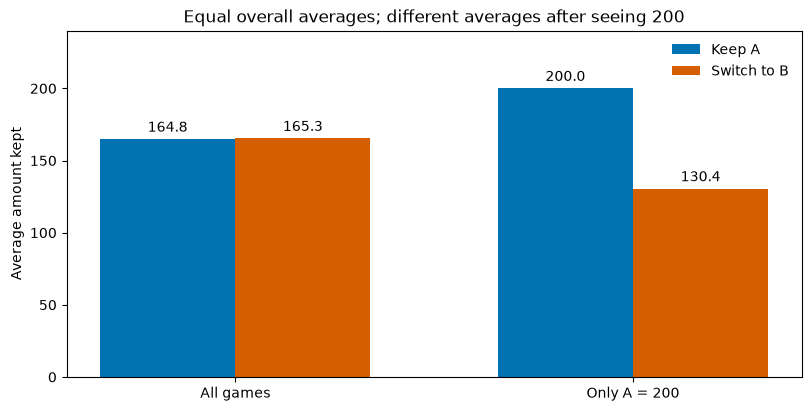

All games: keep 164.81, switch 165.32 (both approach 165).


In [5]:
keep_means = [A.mean(), A[observed].mean()]
switch_means = [B.mean(), B[observed].mean()]
positions = np.arange(2)
width = 0.34
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
keep_bars = ax.bar(positions - width / 2, keep_means, width,
                   label='Keep A', color=blue)
switch_bars = ax.bar(positions + width / 2, switch_means, width,
                     label='Switch to B', color=orange)
ax.bar_label(keep_bars, fmt='%.1f', padding=3)
ax.bar_label(switch_bars, fmt='%.1f', padding=3)
ax.set(xticks=positions, xticklabels=['All games', 'Only A = 200'],
       ylabel='Average amount kept', ylim=(0, 240),
       title='Equal overall averages; different averages after seeing 200')
ax.legend(frameon=False)
plt.show()

assert exact_A.mean() == exact_B.mean() == 165
assert (exact_B - exact_A).mean() == 0
print(f'All games: keep {A.mean():.2f}, switch {B.mean():.2f} (both approach 165).')

## Switching back uses the information you already have

Suppose you saw 200, switched, and now see 100. You know the other envelope still contains 200. Switching back recovers it; no fresh 50/50 gamble appeared.

If you switched from 200 and found 400, you would keep 400. Neither case justifies repeatedly treating the other envelope as a new equally likely choice between half and double.

The probabilities depend on how the pair was generated. Without that information, seeing $a$ alone does not supply the probabilities needed for this expected-value calculation.